In [3]:
import pandas as pd
import numpy as np
from pathlib import Path

BASE_DIR = Path("../data/raw")

df = pd.read_csv(BASE_DIR / "ptbxl_database.csv")
scp = pd.read_csv(BASE_DIR / "scp_statements.csv", index_col=0)

print("Dataset shape:", df.shape)
print("Unique patients:", df["patient_id"].nunique())
print("Missing values:", df.isnull().sum().sum())

display(df.head())

Dataset shape: (21799, 28)
Unique patients: 18869
Missing values: 207475


,ecg_id,patient_id,age,sex,height,weight,nurse,site,device,recording_date,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
0,1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,...,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
1,2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,...,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
2,3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,...,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr
3,4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,...,True,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr
4,5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,...,True,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr


In [4]:
print("SCP Statements:")
display(scp.head(10))

print("Total SCP codes:", len(scp))

print("\nDiagnostic classes:")
display(
    scp[scp["diagnostic"] == 1][
        ["description", "diagnostic_class", "diagnostic_subclass"]
    ]
)

print("\nECG labels:")
display(df["scp_codes"].head(10))

SCP Statements:


,description,diagnostic,form,rhythm,diagnostic_class,diagnostic_subclass,Statement Category,SCP-ECG Statement Description,AHA code,aECG REFID,CDISC Code,DICOM Code
NDT,non-diagnostic T abnormalities,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,non-diagnostic T abnormalities,NaN,NaN,NaN,NaN
NST_,non-specific ST changes,1.0,1.0,NaN,STTC,NST_,Basic roots for coding ST-T changes and abnorm...,non-specific ST changes,145.0,MDC_ECG_RHY_STHILOST,NaN,NaN
DIG,digitalis-effect,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,suggests digitalis-effect,205.0,NaN,NaN,NaN
LNGQT,long QT-interval,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,long QT-interval,148.0,NaN,NaN,NaN
NORM,normal ECG,1.0,NaN,NaN,NORM,NORM,Normal/abnormal,normal ECG,1.0,NaN,NaN,F-000B7
IMI,inferior myocardial infarction,1.0,NaN,NaN,MI,IMI,Myocardial Infarction,inferior myocardial infarction,161.0,NaN,NaN,NaN
ASMI,anteroseptal myocardial infarction,1.0,NaN,NaN,MI,AMI,Myocardial Infarction,anteroseptal myocardial infarction,165.0,NaN,NaN,NaN
LVH,left ventricular hypertrophy,1.0,NaN,NaN,HYP,LVH,Ventricular Hypertrophy,left ventricular hypertrophy,142.0,NaN,C71076,NaN
LAFB,left anterior fascicular block,1.0,NaN,NaN,CD,LAFB/LPFB,Intraventricular and intra-atrial Conduction d...,left anterior fascicular block,101.0,MDC_ECG_BEAT_BLK_ANT_L_HEMI,C62267,D3-33140
ISC_,non-specific ischemic,1.0,NaN,NaN,STTC,ISC_,Basic roots for coding ST-T changes and abnorm...,ischemic ST-T changes,226.0,NaN,NaN,NaN


Total SCP codes: 71

Diagnostic classes:


,description,diagnostic_class,diagnostic_subclass
NDT,non-diagnostic T abnormalities,STTC,STTC
NST_,non-specific ST changes,STTC,NST_
DIG,digitalis-effect,STTC,STTC
LNGQT,long QT-interval,STTC,STTC
NORM,normal ECG,NORM,NORM
IMI,inferior myocardial infarction,MI,IMI
ASMI,anteroseptal myocardial infarction,MI,AMI
LVH,left ventricular hypertrophy,HYP,LVH
LAFB,left anterior fascicular block,CD,LAFB/LPFB
ISC_,non-specific ischemic,STTC,ISC_



ECG labels:


0    {'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}
1                {'NORM': 80.0, 'SBRAD': 0.0}
2                  {'NORM': 100.0, 'SR': 0.0}
3                  {'NORM': 100.0, 'SR': 0.0}
4                  {'NORM': 100.0, 'SR': 0.0}
5                  {'NORM': 100.0, 'SR': 0.0}
6                  {'NORM': 100.0, 'SR': 0.0}
7      {'IMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}
8                  {'NORM': 100.0, 'SR': 0.0}
9                  {'NORM': 100.0, 'SR': 0.0}
Name: scp_codes, dtype: str

In [5]:
from ast import literal_eval
from collections import Counter

counts = Counter()

for codes in df["scp_codes"]:
    codes = literal_eval(codes) if isinstance(codes, str) else codes

    for code, score in codes.items():
        if code in scp.index and scp.loc[code, "diagnostic"] == 1:
            cls = scp.loc[code, "diagnostic_class"]
            counts[cls] += 1

print(counts)

Counter({'NORM': 9514, 'MI': 6863, 'STTC': 5771, 'CD': 5761, 'HYP': 2812})


## signal processing

In [2]:
import pandas as pd
import wfdb
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR = Path("../data/raw")

df = pd.read_csv(BASE_DIR / "ptbxl_database.csv")

record_path = BASE_DIR / df.iloc[0]["filename_lr"]

record = wfdb.rdrecord(str(record_path))

signal = record.p_signal

print("Signal shape:", signal.shape)
print("Sampling frequency:", record.fs)
print("Leads:", record.sig_name)

Signal shape: (1000, 12)
Sampling frequency: 100
Leads: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


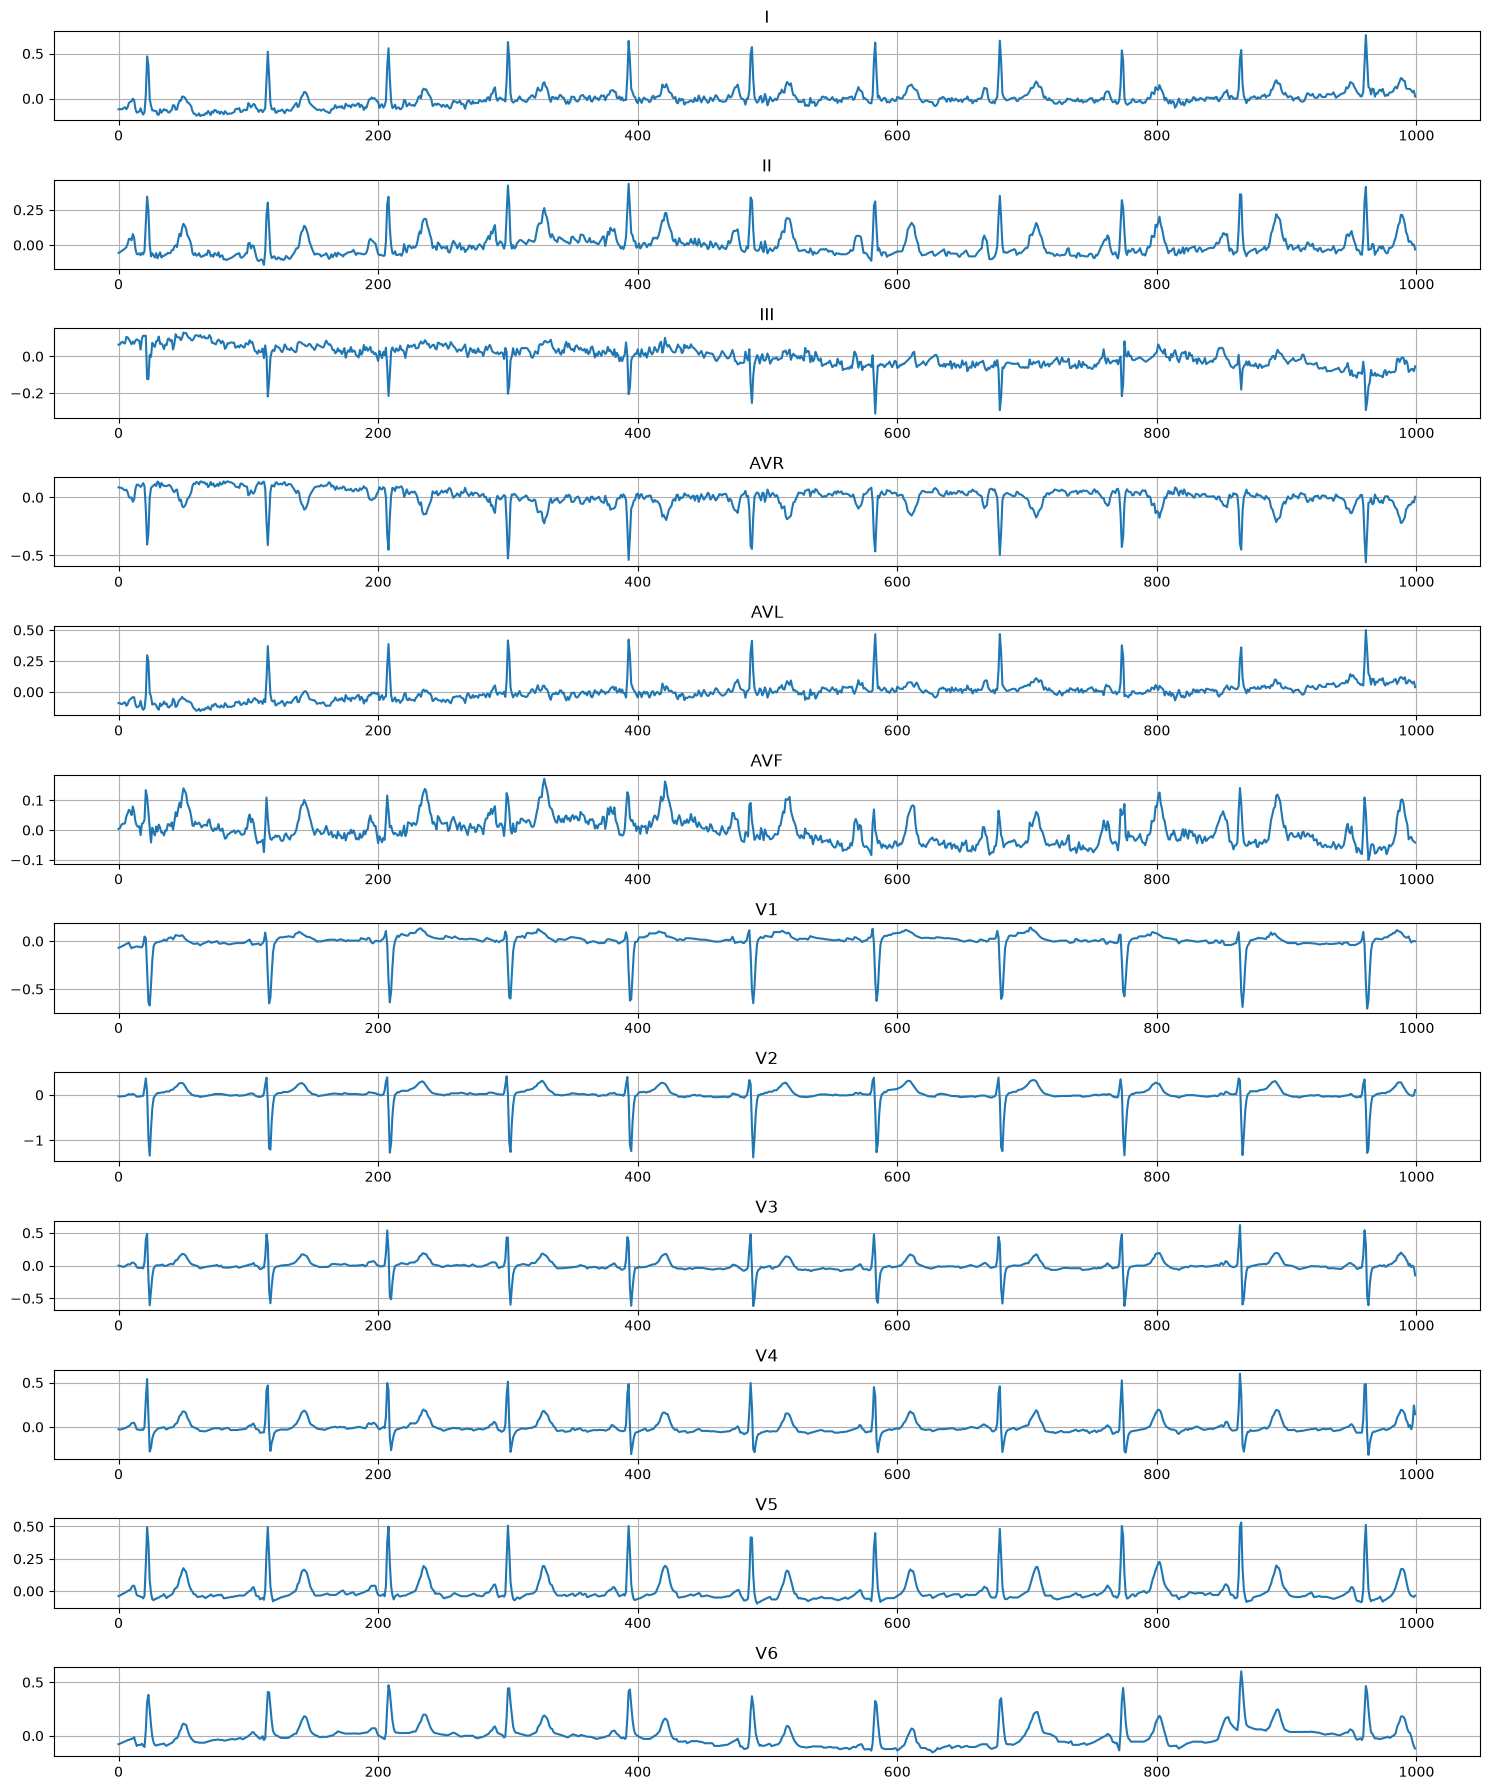

In [3]:
fig, axes = plt.subplots(12, 1, figsize=(15, 18))

for i, ax in enumerate(axes):
    ax.plot(signal[:, i])
    ax.set_title(record.sig_name[i])
    ax.grid(True)

plt.tight_layout()
plt.show()

In [6]:
from scipy.signal import butter, sosfiltfilt

def bandpass_filter(signal, lowcut=0.5, highcut=40, fs=100, order=4):
    sos = butter(
        order,
        [lowcut, highcut],
        btype="bandpass",
        fs=fs,
        output="sos"
    )
    return sosfiltfilt(sos, signal, axis=0)

filtered_signal = bandpass_filter(signal)

print("Original:", signal.shape)
print("Filtered:", filtered_signal.shape)

Original: (1000, 12)
Filtered: (1000, 12)


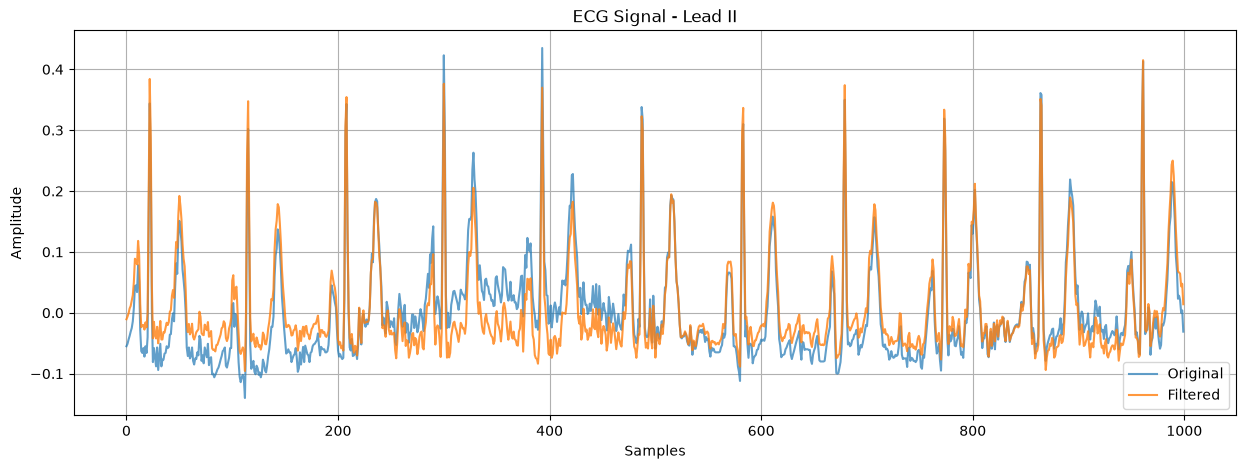

In [7]:
import matplotlib.pyplot as plt

lead = 1  # Lead II

plt.figure(figsize=(15, 5))
plt.plot(signal[:, lead], label="Original", alpha=0.7)
plt.plot(filtered_signal[:, lead], label="Filtered", alpha=0.8)

plt.title("ECG Signal - Lead II")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

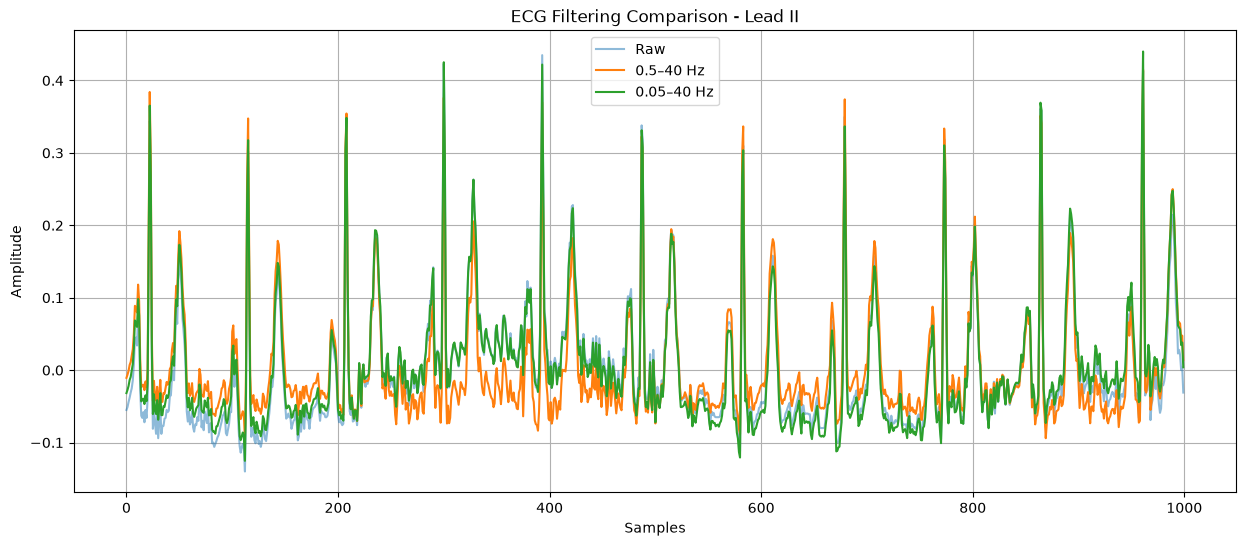

In [8]:
def apply_filter(signal, lowcut, highcut=40, fs=100):
    sos = butter(
        4,
        [lowcut, highcut],
        btype="bandpass",
        fs=fs,
        output="sos"
    )
    return sosfiltfilt(sos, signal, axis=0)


filtered_05 = apply_filter(signal, 0.5)
filtered_005 = apply_filter(signal, 0.05)

lead = 1  # Lead II

plt.figure(figsize=(15, 6))

plt.plot(signal[:, lead], label="Raw", alpha=0.5)
plt.plot(filtered_05[:, lead], label="0.5–40 Hz")
plt.plot(filtered_005[:, lead], label="0.05–40 Hz")

plt.title("ECG Filtering Comparison - Lead II")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

In [11]:
import numpy as np
import wfdb
from scipy.signal import butter, sosfiltfilt
from tqdm.notebook import tqdm

# Filter configuration
FS = 100
LOWCUT = 0.05
HIGHCUT = 40

sos = butter(
    4,
    [LOWCUT, HIGHCUT],
    btype="bandpass",
    fs=FS,
    output="sos"
)

# Process all signals
X_filtered = []

for filename in tqdm(df["filename_lr"]):

    record_path = BASE_DIR / filename
    record = wfdb.rdrecord(str(record_path))

    signal = record.p_signal.astype(np.float32)

    filtered = sosfiltfilt(sos, signal, axis=0)

    X_filtered.append(filtered.astype(np.float32))

X_filtered = np.stack(X_filtered)

print("Processed shape:", X_filtered.shape)
print("Data type:", X_filtered.dtype)
print("NaN values:", np.isnan(X_filtered).sum())
print("Infinite values:", np.isinf(X_filtered).sum())

  0%|          | 0/21799 [00:00<?, ?it/s]

Processed shape: (21799, 1000, 12)
Data type: float32
NaN values: 0
Infinite values: 0


In [12]:
import os

PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

np.save(PROCESSED_DIR / "X_filtered.npy", X_filtered)

print("Saved successfully!")

Saved successfully!


## Normalization

In [13]:
# Official PTB-XL split
train_idx = df["strat_fold"].between(1, 8)
val_idx = df["strat_fold"] == 9
test_idx = df["strat_fold"] == 10

print("Train:", train_idx.sum())
print("Validation:", val_idx.sum())
print("Test:", test_idx.sum())

Train: 17418
Validation: 2183
Test: 2198


In [14]:
X_train = X_filtered[train_idx]

mean = X_train.mean(axis=(0, 1), keepdims=True)
std = X_train.std(axis=(0, 1), keepdims=True)

std = np.where(std == 0, 1, std)

print("Mean shape:", mean.shape)
print("Std shape:", std.shape)

Mean shape: (1, 1, 12)
Std shape: (1, 1, 12)


In [15]:
X_normalized = (X_filtered - mean) / std

print("Shape:", X_normalized.shape)
print("Mean:", X_normalized.mean(axis=(0, 1)))
print("Std:", X_normalized.std(axis=(0, 1)))
print("NaN:", np.isnan(X_normalized).sum())
print("Inf:", np.isinf(X_normalized).sum())

Shape: (21799, 1000, 12)
Mean: [ 9.6697552e-04  3.8219259e-05 -9.2791108e-04 -5.8105204e-04
  1.1154281e-03 -4.8222108e-04 -2.1688426e-03 -5.9181917e-04
 -5.0980179e-04  5.4032257e-04  4.6204421e-04  2.0943235e-03]
Std: [0.9944822  0.9980605  0.99453586 0.99686056 0.99288553 0.9964112
 0.99962074 0.9999385  0.99848276 0.99434954 0.9948425  1.0062703 ]
NaN: 0
Inf: 0


In [16]:
np.save(PROCESSED_DIR / "X_normalized.npy", X_normalized)

np.savez(
    PROCESSED_DIR / "normalization_params.npz",
    mean=mean,
    std=std
)

print("Normalized signals and parameters saved!")

Normalized signals and parameters saved!


## Data Preparation

In [17]:
import ast
import pandas as pd
import numpy as np

scp = pd.read_csv(BASE_DIR / "scp_statements.csv", index_col=0)

diagnostic_classes = ["NORM", "MI", "STTC", "CD", "HYP"]

print(scp[["diagnostic", "diagnostic_class"]].head())

       diagnostic diagnostic_class
NDT           1.0             STTC
NST_          1.0             STTC
DIG           1.0             STTC
LNGQT         1.0             STTC
NORM          1.0             NORM


In [18]:
def extract_labels(scp_codes):
    codes = ast.literal_eval(scp_codes)

    labels = []

    for code, score in codes.items():

        if code in scp.index:
            row = scp.loc[code]

            if row["diagnostic"] == 1 and score > 0:
                labels.append(row["diagnostic_class"])

    return labels


Y = np.zeros((len(df), len(diagnostic_classes)), dtype=np.float32)

for i, scp_codes in enumerate(df["scp_codes"]):

    labels = extract_labels(scp_codes)

    for label in labels:
        if label in diagnostic_classes:
            Y[i, diagnostic_classes.index(label)] = 1


print("Y shape:", Y.shape)
print("Total labels:", Y.sum(axis=0))

Y shape: (21799, 5)
Total labels: [9514. 5469. 5108. 4898. 2649.]


In [19]:
labels_per_record = Y.sum(axis=1)

print("No labels:", np.sum(labels_per_record == 0))
print("One label:", np.sum(labels_per_record == 1))
print("Multiple labels:", np.sum(labels_per_record > 1))
print("Maximum labels per ECG:", labels_per_record.max())

No labels: 424
One label: 16307
Multiple labels: 5068
Maximum labels per ECG: 4.0


In [20]:
valid_mask = Y.sum(axis=1) > 0

X_final = X_normalized[valid_mask]
Y_final = Y[valid_mask]

df_final = df.loc[valid_mask].reset_index(drop=True)

print("X:", X_final.shape)
print("Y:", Y_final.shape)
print("Records:", len(df_final))

X: (21375, 1000, 12)
Y: (21375, 5)
Records: 21375


In [21]:
train_mask = df_final["strat_fold"].between(1, 8)
val_mask = df_final["strat_fold"] == 9
test_mask = df_final["strat_fold"] == 10

X_train = X_final[train_mask]
X_val = X_final[val_mask]
X_test = X_final[test_mask]

Y_train = Y_final[train_mask]
Y_val = Y_final[val_mask]
Y_test = Y_final[test_mask]

print("Train:", X_train.shape, Y_train.shape)
print("Validation:", X_val.shape, Y_val.shape)
print("Test:", X_test.shape, Y_test.shape)

Train: (17073, 1000, 12) (17073, 5)
Validation: (2145, 1000, 12) (2145, 5)
Test: (2157, 1000, 12) (2157, 5)


In [22]:
np.savez_compressed(
    PROCESSED_DIR / "ecg_dataset.npz",
    X_train=X_train,
    Y_train=Y_train,
    X_val=X_val,
    Y_val=Y_val,
    X_test=X_test,
    Y_test=Y_test
)

print("Dataset saved successfully!")

Dataset saved successfully!


## Machine Learning


In [24]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

from src.model import build_cnn

model = build_cnn()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 994, 64)        │         5,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 994, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 497, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 493, 128)       │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 493, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 246, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 244, 256)       │        98,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 244, 256)       │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 180,421 (704.77 KB)

 Trainable params: 179,525 (701.27 KB)

 Non-trainable params: 896 (3.50 KB)